<a href="https://colab.research.google.com/github/anupbagale/Image_Processing/blob/main/notebooks/04_histogram_equalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Histogram equalization

Histogram equalization spreads out the most frequent grey levels so that the output histogram is
roughly flat. Unlike contrast stretching, the mapping is not linear: it is the cumulative
distribution function (CDF) of the image, scaled to 0 to 255.

For an image with $N$ pixels and histogram $h(k)$, the CDF is $c(r) = \sum_{k=0}^{r} h(k)$ and
each grey level $r$ is mapped to

$$s = \operatorname{round}\left(\frac{c(r) - c_{min}}{N - c_{min}} \cdot 255\right)$$

where $c_{min}$ is the smallest non-zero value of the CDF. Subtracting $c_{min}$ makes the
darkest grey level in the image map to 0.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

In [2]:
image = data.moon()

## Implementation

Because the mapping only depends on the grey level, it can be stored as a lookup table of 256
values and applied to all pixels at once with `lut[image]`.

In [3]:
def histogram_equalization(image):
    histogram = np.bincount(image.ravel(), minlength=256)
    cdf = histogram.cumsum()
    cdf_min = cdf[cdf > 0][0]
    lut = np.round((cdf - cdf_min) / (image.size - cdf_min) * 255)
    lut = np.clip(lut, 0, 255).astype(np.uint8)
    return lut[image], histogram


equalized, histogram = histogram_equalization(image)
equalized_histogram = np.bincount(equalized.ravel(), minlength=256)

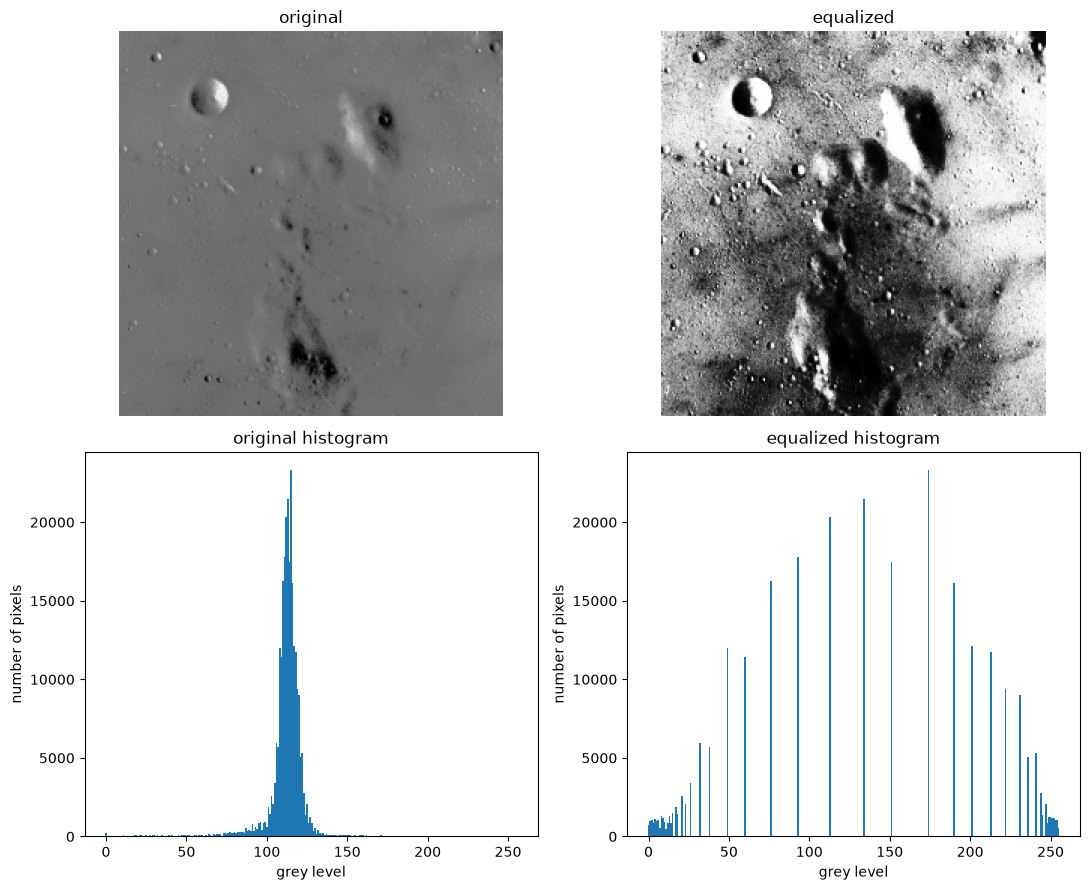

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
ax[0, 0].imshow(image, vmin=0, vmax=255); ax[0, 0].set_title("original")
ax[0, 1].imshow(equalized, vmin=0, vmax=255); ax[0, 1].set_title("equalized")
for a in ax[0]:
    a.axis("off")

ax[1, 0].bar(range(256), histogram, width=1)
ax[1, 0].set_title("original histogram")
ax[1, 1].bar(range(256), equalized_histogram, width=1)
ax[1, 1].set_title("equalized histogram")
for a in ax[1]:
    a.set_xlabel("grey level")
    a.set_ylabel("number of pixels")
plt.tight_layout()
plt.show()

The equalized histogram is not perfectly flat. Pixels that share a grey level always map to the
same new level, so a histogram bar can be moved but never split. What does become close to a
straight line is the CDF:

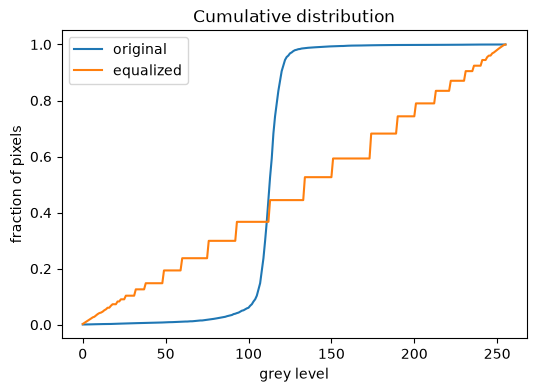

In [5]:
plt.figure(figsize=(6, 4))
plt.plot(np.cumsum(histogram) / image.size, label="original")
plt.plot(np.cumsum(equalized_histogram) / image.size, label="equalized")
plt.xlabel("grey level")
plt.ylabel("fraction of pixels")
plt.title("Cumulative distribution")
plt.legend()
plt.show()

## Comparison with OpenCV

`cv2.equalizeHist` uses the same formula, so the two results should be identical.

An earlier version of this notebook used `cdf / cdf.max()` without subtracting $c_{min}$, and
converted to integers without rounding. That gives results up to one grey level away from OpenCV.

In [6]:
opencv = cv2.equalizeHist(image)
print("same as cv2.equalizeHist:", np.array_equal(equalized, opencv))

same as cv2.equalizeHist: True
